In [1]:
# Cell 1: Setup & Config
import numpy as np
import pandas as pd
import gc, json, time
from pathlib import Path
from scipy.ndimage import median_filter

CFG = {
    'input_dir':  Path('./Test signals from previous years/Suction data/Original'),
    'output_dir': Path('./Test signals from previous years/Suction data/Preprocessed'),

    'original_fs': 50_000,     # Hz
    'target_fs':   500,        # Hz
    'adc_column':  'adc2',      # column name if header exists
    'adc_col_index': None,     # fallback: index of ADC column if no header (set to int)

    'chunk_rows': 10_000_000,  # rows read per chunk (only the ADC column is in RAM)
    'baseline_sec': 5.0,       # rolling-median window for baseline removal
    'uint16_offset': 32_768,   # centered values can be negative → add this before casting
    'overwrite': False,        # True = reprocess even if .bin exists
}
CFG['pool_block'] = CFG['original_fs'] // CFG['target_fs']
CFG['output_dir'].mkdir(parents=True, exist_ok=True)
print(f"✅ Config: {CFG['original_fs']}→{CFG['target_fs']} Hz (block={CFG['pool_block']}), output in {CFG['output_dir']}")

✅ Config: 50000→500 Hz (block=100), output in Test signals from previous years/Suction data/Preprocessed


In [2]:
# Cell 2: File sniffing + chunked single-column reader
def sniff_csv(path):
    """Return (delimiter, has_header, n_columns) from the first line."""
    with open(path, 'r') as f:
        first = f.readline()
    delim = '\t' if first.count('\t') >= first.count(',') else ','
    parts = [p.strip() for p in first.rstrip('\r\n').split(delim) if p != '']
    is_numeric = all(p.lstrip('-').replace('.', '', 1).isdigit() for p in parts)
    return delim, (not is_numeric), len(parts)

def load_adc_chunks(path, cfg):
    """Yield the ADC column as float32 arrays, one chunk at a time."""
    delim, header, ncols = sniff_csv(path)
    if header:
        cols = pd.read_csv(path, sep=delim, nrows=0).columns.tolist()
        usecols = cfg['adc_column'] if cfg['adc_column'] in cols else cols[cfg['adc_col_index']]
    else:
        usecols = cfg['adc_col_index']

    for chunk in pd.read_csv(path, sep=delim, usecols=[usecols],
                             header=0 if header else None,
                             chunksize=cfg['chunk_rows'],
                             dtype=np.float32, engine='c'):
        yield chunk.iloc[:, 0].to_numpy(dtype=np.float32)
        del chunk

In [3]:
# Cell 3: Block-mean downsampling (no cross-chunk state, no edge artifacts)
def pool_downsample(chunks, block):
    """Mean-pool every `block` raw samples → 1 output sample.
    Leftover (< block) samples at file end become one final partial-block mean."""
    parts, carry = [], np.empty(0, dtype=np.float32)
    total_raw = 0
    for arr in chunks:
        total_raw += len(arr)
        arr = np.concatenate([carry, arr]) if len(carry) else arr
        n_blocks = len(arr) // block
        if n_blocks:
            usable = n_blocks * block
            parts.append(arr[:usable].reshape(n_blocks, block).mean(axis=1, dtype=np.float32))
            carry = arr[usable:].copy()
        else:
            carry = arr
        del arr
    if len(carry):
        parts.append(np.array([carry.mean()], dtype=np.float32))
    return np.concatenate(parts), total_raw

In [4]:
# Cell 4: Full single-file preprocessing (decimate → baseline → uint16 .bin + sidecar)
def preprocess_file(csv_path, cfg):
    bin_path  = cfg['output_dir'] / (csv_path.stem + '.bin')
    meta_path = cfg['output_dir'] / (csv_path.stem + '.meta.json')

    if bin_path.exists() and not cfg['overwrite']:
        print(f"⏭️  {csv_path.name}: .bin already exists (set overwrite=True to redo)")
        return bin_path

    t0 = time.time()
    raw_mb = csv_path.stat().st_size / 1024**2

    # 1. Read + downsample
    pooled, n_raw = pool_downsample(load_adc_chunks(csv_path, cfg), cfg['pool_block'])
    expected = n_raw / cfg['pool_block']
    assert abs(len(pooled) - expected) <= 1, f"samples lost: {len(pooled)} vs {expected:.1f}"

    # 2. Baseline removal (in memory — signal is small now)
    win = int(cfg['baseline_sec'] * cfg['target_fs'])
    win += 1 if win % 2 == 0 else 0
    centered = pooled - median_filter(pooled, size=win)

    # 3. Quantize to uint16 (offset handles negative centered values)
    u16 = np.clip(centered + cfg['uint16_offset'], 0, 65_535).astype(np.uint16)
    u16.tofile(bin_path)

    meta = {
        'source_file': csv_path.name,
        'original_size_mb': round(raw_mb, 2),
        'raw_samples': n_raw,
        'raw_fs': cfg['original_fs'],
        'fs': cfg['target_fs'],
        'samples': int(len(u16)),
        'duration_sec': round(len(u16) / cfg['target_fs'], 2),
        'dtype': 'uint16',
        'value_offset': cfg['uint16_offset'],   # real_value = stored - offset
        'baseline_window_sec': cfg['baseline_sec'],
        'preprocess_time_sec': round(time.time() - t0, 1),
    }
    meta_path.write_text(json.dumps(meta, indent=2))

    print(f"✅ {csv_path.name}: {n_raw:,} raw → {len(u16):,} samples "
          f"({meta['duration_sec']}s) | {raw_mb:.0f} MB → {len(u16)*2/1024**2:.1f} MB "
          f"in {meta['preprocess_time_sec']}s")
    return bin_path

In [5]:
# Cell 5: Batch run (smallest file first — sanity check before committing to the big ones)
files = sorted(CFG['input_dir'].glob('*.csv'), key=lambda p: p.stat().st_size)
print(f"📁 {len(files)} files, smallest → largest:\n")
for f in files:
    print(f"   {f.stat().st_size/1024**2:8.1f} MB  {f.name}")

for csv_path in files:
    try:
        preprocess_file(csv_path, CFG)
        gc.collect()
    except Exception as e:
        print(f"❌ {csv_path.name}: {e}")

📁 9 files, smallest → largest:

       29.6 MB  8. suction_MIDDLE_CONC_1ml_(and_no_resuction).csv
       30.2 MB  5. suction_HIGH_CONC_1ml_and_no_resuction.csv
       30.9 MB  9. suction_MIDDLE_CONC_1ml_(and_no_resuction (2)).csv
       55.2 MB  6. suction_MIDDLE_CONC_3ml_(and_no_resuction).csv
      126.4 MB  7. suction_MIDDLE_CONC_2ml_(and_1_times_resuction).csv
      182.7 MB  4. suction_HIGH_CONC_1ml_(and_2_times_resuction).csv
      265.1 MB  3. suction_HIGH_CONC_2ml_(and_2_times_resuction.csv
      343.7 MB  2. suction_HIGH_CONC_4ml_(and_2_times_resuction).csv
     7242.4 MB  1. LONG_suction_HIGH_CONC_4ml_(and_3_times_resuction).csv
✅ 8. suction_MIDDLE_CONC_1ml_(and_no_resuction).csv: 3,444,736 raw → 34,448 samples (68.9s) | 30 MB → 0.1 MB in 0.3s
✅ 5. suction_HIGH_CONC_1ml_and_no_resuction.csv: 3,514,112 raw → 35,142 samples (70.28s) | 30 MB → 0.1 MB in 0.2s
✅ 9. suction_MIDDLE_CONC_1ml_(and_no_resuction (2)).csv: 3,600,768 raw → 36,008 samples (72.02s) | 31 MB → 0.1 MB in 0.3s


✅ 1. LONG_suction_HIGH_CONC_4ml_(and_3_times_resuction).bin: 8,436,530 samples (expect 8,436,530), duration 16873.1s, range [-181, 1727]


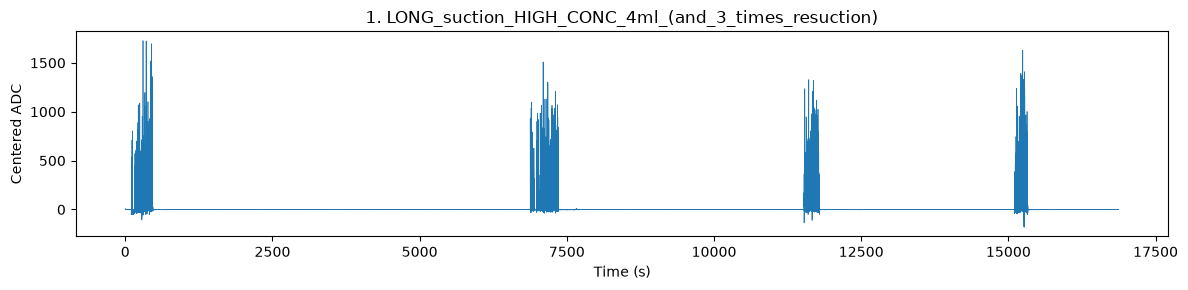

✅ 2. suction_HIGH_CONC_4ml_(and_2_times_resuction).bin: 399,605 samples (expect 399,605), duration 799.2s, range [-77, 2206]


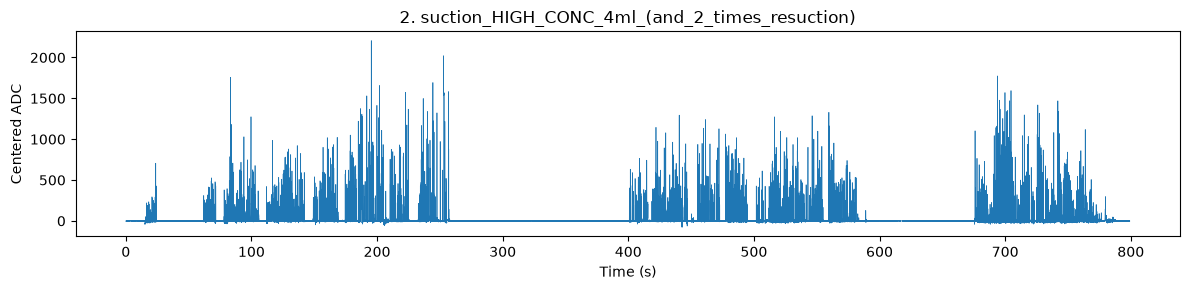

✅ 3. suction_HIGH_CONC_2ml_(and_2_times_resuction.bin: 308,310 samples (expect 308,310), duration 616.6s, range [-48, 1932]


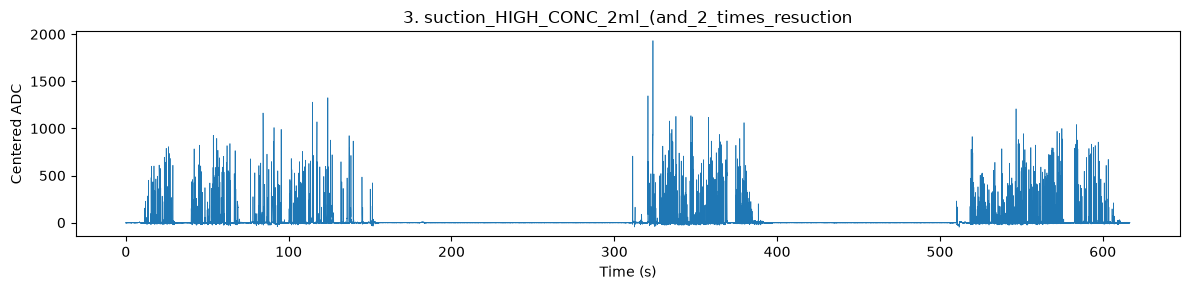

✅ 4. suction_HIGH_CONC_1ml_(and_2_times_resuction).bin: 212,665 samples (expect 212,665), duration 425.3s, range [-48, 2132]


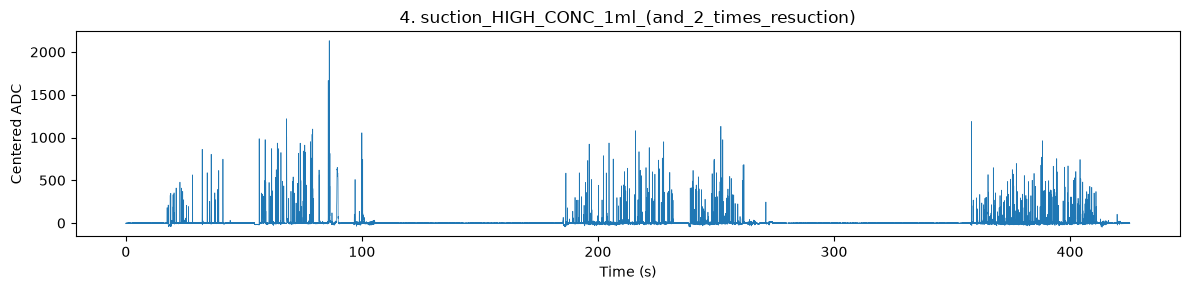

✅ 5. suction_HIGH_CONC_1ml_and_no_resuction.bin: 35,142 samples (expect 35,142), duration 70.3s, range [-45, 1612]


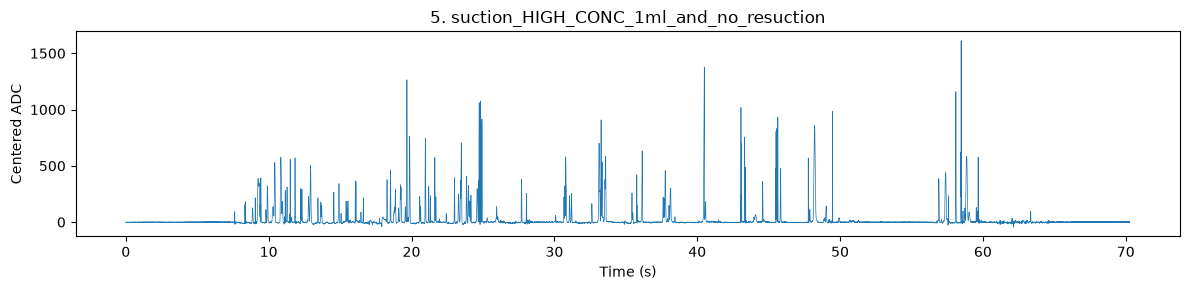

✅ 6. suction_MIDDLE_CONC_3ml_(and_no_resuction).bin: 64,282 samples (expect 64,282), duration 128.6s, range [-51, 972]


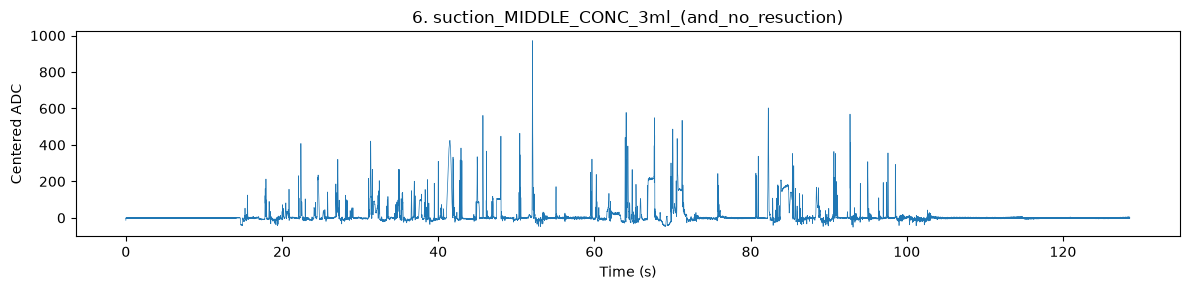

✅ 7. suction_MIDDLE_CONC_2ml_(and_1_times_resuction).bin: 147,295 samples (expect 147,295), duration 294.6s, range [-40, 802]


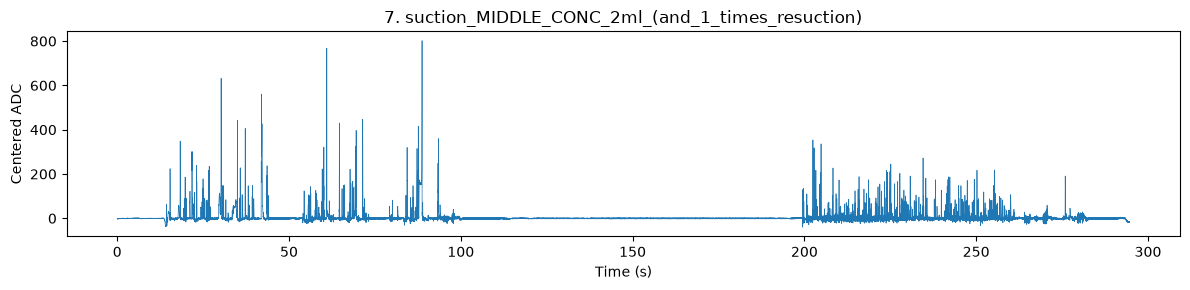

✅ 8. suction_MIDDLE_CONC_1ml_(and_no_resuction).bin: 34,448 samples (expect 34,448), duration 68.9s, range [-45, 850]


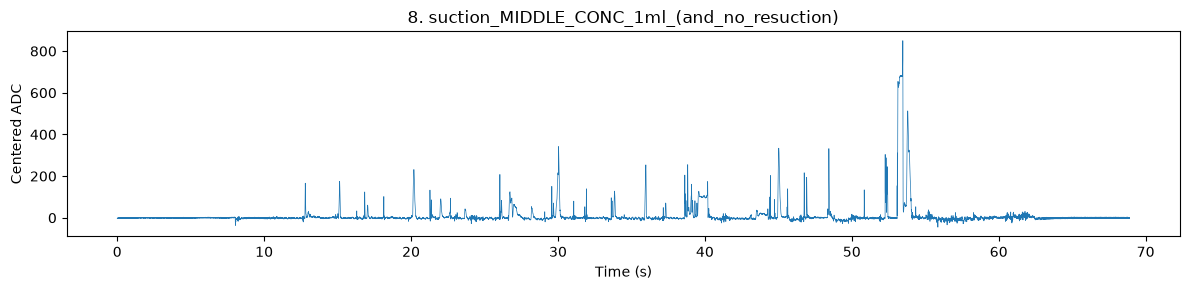

✅ 9. suction_MIDDLE_CONC_1ml_(and_no_resuction (2)).bin: 36,008 samples (expect 36,008), duration 72.0s, range [-47, 429]


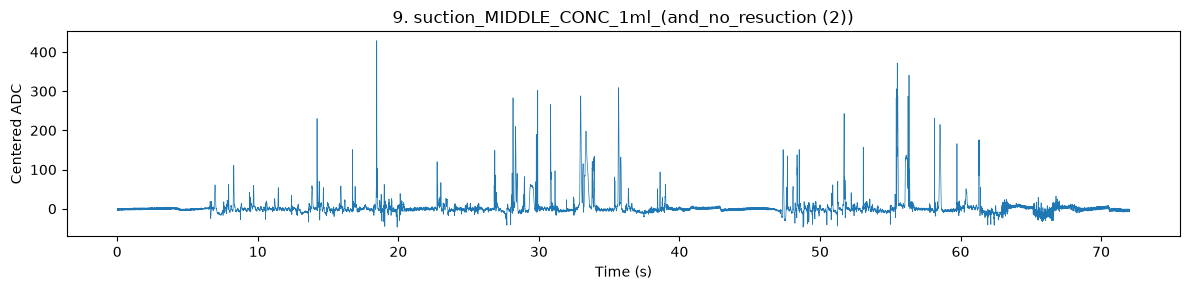

In [6]:
# Cell 6: Verification (checks sample counts against metadata, plots a quick look)
import matplotlib.pyplot as plt

for bin_path in sorted(CFG['output_dir'].glob('*.bin')):
    meta = json.loads((bin_path.with_suffix('.meta.json')).read_text())
    data = np.fromfile(bin_path, dtype=np.uint16).astype(np.int32) - meta['value_offset']
    ok = abs(len(data) - meta['samples']) <= 1
    print(f"{'✅' if ok else '⚠️'} {bin_path.name}: {len(data):,} samples "
          f"(expect {meta['samples']:,}), duration {len(data)/meta['fs']:.1f}s, "
          f"range [{data.min()}, {data.max()}]")

    if data.size:
        fig, ax = plt.subplots(figsize=(12, 3))
        t = np.arange(len(data)) / meta['fs']
        ax.plot(t, data, lw=0.5)
        ax.set(title=bin_path.stem, xlabel='Time (s)', ylabel='Centered ADC')
        plt.tight_layout(); plt.show()

In [7]:
# Cell 1: Peak Detection Configuration
import numpy as np
import json
from pathlib import Path
import time
from scipy.signal import find_peaks
from concurrent.futures import ThreadPoolExecutor
import psutil

PEAK_CONFIG = {
    'data_dir': Path('./Test signals from previous years/Suction data/Preprocessed'),
    
    # Peak detection parameters (tunable)
    'prominence_std_mult': 1.5,    # Sensitivity multiplier
    'min_distance_sec': 0.1,       # Min 100ms between peaks
    'min_width_sec': 0.01,         # Min 10ms peak width
    'max_prominence': None,        # No upper limit (remove false positives)
    
    # Output format
    'output_dir': Path('./Test signals from previous years/Suction data/Results'),
    
    # Partial results strategy
    'report_partial_results': True,  # Show results incrementally
    'partial_interval_samples': 500_000,  # Report every X samples processed
}

PEAK_CONFIG['fs'] = 500  # Hz (from preprocessing)
PEAK_CONFIG['min_distance_samples'] = int(PEAK_CONFIG['min_distance_sec'] * PEAK_CONFIG['fs'])
PEAK_CONFIG['min_width_samples'] = int(PEAK_CONFIG['min_width_sec'] * PEAK_CONFIG['fs'])

PEAK_CONFIG['output_dir'].mkdir(parents=True, exist_ok=True)

print("✅ Peak Detection Configuration")
print(f"   Prominence: {PEAK_CONFIG['prominence_std_mult']}× std")
print(f"   Min distance: {PEAK_CONFIG['min_distance_sec']*1000:.0f} ms")
print(f"   Data dir: {PEAK_CONFIG['data_dir']}")
print(f"   Partial reporting: ON (every {PEAK_CONFIG['partial_interval_samples']:,} samples)")

✅ Peak Detection Configuration
   Prominence: 1.5× std
   Min distance: 100 ms
   Data dir: Test signals from previous years/Suction data/Preprocessed
   Partial reporting: ON (every 500,000 samples)


In [8]:
# Cell 2: Fast Peak Detection (Single File, Memory-Mapped)
def detect_peaks_fast(bin_path):
    """
    Memory-efficient peak detection using memory-mapped file.
    Returns peak indices and their heights.
    """
    meta_path = bin_path.with_suffix('.meta.json')
    if not meta_path.exists():
        raise FileNotFoundError(f"No metadata found for {bin_path}")
    
    meta = json.loads(meta_path.read_text())
    
    # Memory-map the binary file (no full load into RAM)
    data = np.memmap(str(bin_path), dtype='uint16', mode='r')
    
    # Convert back to signed values (reverse preprocessing offset)
    centered = (data.astype(np.int32) - meta['value_offset'])
    del data  # Free the memmap reference
    
    # Calculate noise floor and prominence threshold
    baseline_std = np.std(centered)
    prominence_threshold = PEAK_CONFIG['prominence_std_mult'] * baseline_std
    
    # Find peaks
    peaks, properties = find_peaks(
        centered,
        prominence=prominence_threshold,
        distance=PEAK_CONFIG['min_distance_samples'],
        width=PEAK_CONFIG['min_width_samples'],
    )
    
    # Extract peak heights
    peak_heights = centered[peaks]
    
    return {
        'peaks': peaks,
        'heights': peak_heights,
        'num_peaks': len(peaks),
        'baseline_std': baseline_std,
        'prominence_threshold': prominence_threshold,
        'duration_sec': len(centered) / PEAK_CONFIG['fs'],
        'samples_total': len(centered),
    }

In [9]:
# Cell 3: Streaming Peak Detection with Partial Results
# Crucial for the 7-hour file - report results while still processing

def detect_peaks_streaming(bin_path, partial_callback=None):
    """
    Process file in chunks, detecting peaks incrementally.
    Callback receives partial results after each chunk.
    """
    meta_path = bin_path.with_suffix('.meta.json')
    meta = json.loads(meta_path.read_text())
    
    total_samples = meta['samples']
    fs = PEAK_CONFIG['fs']
    
    # Open memory-mapped file
    data = np.memmap(str(bin_path), dtype='uint16', mode='r')
    
    # State for overlapping chunk detection
    overlap_samples = PEAK_CONFIG['min_distance_samples'] * 2
    
    all_peaks = []
    all_heights = []
    processed = 0
    chunk_size = PEAK_CONFIG['partial_interval_samples']
    
    chunk_start = 0
    while chunk_start < total_samples:
        chunk_end = min(chunk_start + chunk_size + overlap_samples, total_samples)
        chunk_size_actual = chunk_end - chunk_start
        
        # Load chunk (minus overlap padding for clean boundaries)
        chunk = (data[chunk_start:chunk_end].astype(np.int32) - meta['value_offset'])
        
        # Detect peaks in this chunk
        peaks, properties = find_peaks(
            chunk,
            prominence=PEAK_CONFIG['prominence_std_mult'] * np.std(chunk),
            distance=PEAK_CONFIG['min_distance_samples'],
            width=PEAK_CONFIG['min_width_samples'],
        )
        
        # Adjust peak indices to global coordinates
        global_peaks = peaks + chunk_start
        all_peaks.extend(global_peaks.tolist())
        all_heights.extend(chunk[peaks].tolist())
        
        processed += chunk_size_actual
        
        if partial_callback and processed % PEAK_CONFIG['partial_interval_samples'] < chunk_size:
            partial_callback(len(all_peaks), processed, total_samples)
        
        del chunk
        chunk_start += chunk_size
    
    del data
    
    return {
        'peaks': np.array(all_peaks),
        'heights': np.array(all_heights),
        'num_peaks': len(all_peaks),
        'duration_sec': total_samples / fs,
    }

In [10]:
# Cell 4: Single-File Benchmark (Test on Small File First)
def benchmark_peak_detection(bin_path):
    """Measure exact timing for peak detection"""
    print(f"\n⏱️  Benchmarking: {bin_path.name}")
    
    # Method 1: Full detection
    t0 = time.time()
    result = detect_peaks_fast(bin_path)
    t1 = time.time()
    
    print(f"   Total samples: {result['samples_total']:,}")
    print(f"   Peaks detected: {result['num_peaks']:,}")
    print(f"   Detection rate: {result['num_peaks']/result['duration_sec']:.1f} peaks/sec")
    print(f"   Baseline noise: {result['baseline_std']:.1f}")
    print(f"   Threshold: {result['prominence_threshold']:.1f}")
    print(f"   ⚡ Detection time: {(t1-t0)*1000:.1f} ms")
    
    return result

In [11]:
# Cell 5: Test on Small File
small_files = sorted(PEAK_CONFIG['data_dir'].glob('*.bin'), key=lambda p: p.stat().st_size)[:2]

for bin_path in small_files:
    try:
        result = benchmark_peak_detection(bin_path)
    except Exception as e:
        print(f"❌ {bin_path.name}: {e}")


⏱️  Benchmarking: 8. suction_MIDDLE_CONC_1ml_(and_no_resuction).bin
   Total samples: 34,448
   Peaks detected: 27
   Detection rate: 0.4 peaks/sec
   Baseline noise: 59.3
   Threshold: 89.0
   ⚡ Detection time: 3.7 ms

⏱️  Benchmarking: 5. suction_HIGH_CONC_1ml_and_no_resuction.bin
   Total samples: 35,142
   Peaks detected: 65
   Detection rate: 0.9 peaks/sec
   Baseline noise: 97.3
   Threshold: 146.0
   ⚡ Detection time: 1.6 ms


In [12]:
# Cell 6: Full Batch Detection with Timing
def run_full_detection():
    """Process all .bin files, report per-file timing"""
    bin_files = sorted(PEAK_CONFIG['data_dir'].glob('*.bin'), key=lambda p: p.stat().st_size)
    
    print("\n" + "="*60)
    print("🔍 BATCH PEAK DETECTION")
    print("="*60)
    
    results = []
    total_time = 0
    
    for i, bin_path in enumerate(bin_files):
        start = time.time()
        print(f"\n[{i+1}/{len(bin_files)}] {bin_path.name}")
        
        try:
            result = detect_peaks_fast(bin_path)
            elapsed = time.time() - start
            total_time += elapsed
            
            status = "✓" if elapsed < 3.0 else "⚠️ SLOW"
            print(f"   {status} {result['num_peaks']:,} peaks in {elapsed*1000:.1f} ms")
            
            results.append({
                'file': bin_path.name,
                'num_peaks': result['num_peaks'],
                'duration_sec': result['duration_sec'],
                'peaks_per_min': round(result['num_peaks'] / (result['duration_sec']/60), 2),
                'detection_ms': round(elapsed * 1000, 1),
                'passed_target': elapsed < 3.0,
            })
        except Exception as e:
            print(f"   ❌ ERROR: {e}")
            results.append({
                'file': bin_path.name,
                'error': str(e),
                'detection_ms': None,
                'passed_target': False,
            })
    
    # Summary
    print("\n" + "="*60)
    print("📊 DETECTION SUMMARY")
    print("="*60)
    
    passed = sum(1 for r in results if r.get('passed_target'))
    print(f"   Files processed: {len(results)}")
    print(f"   Passed 3s target: {passed}/{len(results)} ({passed/len(results)*100:.0f}%)")
    print(f"   Total time: {total_time:.1f}s")
    
    return results

In [13]:
# Cell 7: Save Results to CSV/JSON
def save_detection_results(results):
    """Save all results for downstream analysis"""
    import pandas as pd
    
    df = pd.DataFrame(results)
    df.to_csv(PEAK_CONFIG['output_dir'] / 'detection_results.csv', index=False)
    
    with open(PEAK_CONFIG['output_dir'] / 'detection_summary.json', 'w') as f:
        json.dump({
            'files_processed': len(results),
            'passed_target': sum(1 for r in results if r.get('passed_target')),
            'failed': sum(1 for r in results if 'error' in r),
            'total_time_sec': sum(r['detection_ms'] for r in results if r.get('detection_ms')) / 1000,
            'per_file': results
        }, f, indent=2)
    
    print(f"💾 Results saved to {PEAK_CONFIG['output_dir']}")

In [ ]:
# RUN THE FULL BATCH DETECTION NOW

print("="*60)
print("🚀 RUNNING FULL PEAK DETECTION BATCH")
print("="*60)

# Create output directory if it doesn't exist
PEAK_CONFIG['output_dir'].mkdir(parents=True, exist_ok=True)

# Run the full detection
results = run_full_detection()

# SAVE THE RESULTS TO DISK

save_detection_results(results)

print("\n" + "="*60)
print("✅ ALL DONE!")
print("="*60)